# 02 · Dynamic Programming

We solve the finite-horizon Bellman recursion by backward induction and extract the optimal policy and its **no-trade region**.

$$g_t(x)=\max_y\ m(x,y)^{1-\gamma}\,\mathbb{E}_R\!\big[\phi(y,R)^{1-\gamma}\,g_{t+1}(x'(y,R))\big],\qquad g_N(x)=\tfrac{1}{1-\gamma},$$
with $\phi(y,R)=yR+(1-y)R_f$ and $x'=yR/\phi$.

In [1]:
import os, sys
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt


In [2]:
from src.config import Config
from src.dp_solver import solve
from src import visualization as viz
cfg = Config()
import time; t0=time.time()
sol = solve(cfg)
print(f'Solved {cfg.n_steps}-step DP on a {cfg.n_x}-point grid in {time.time()-t0:.3f}s')
lo,hi = sol.no_trade_band(0)
print(f'No-trade band at t=0: [{lo:.4f}, {hi:.4f}] (width {hi-lo:.4f}); Merton w*={cfg.merton_fraction:.4f}')

Solved 52-step DP on a 201-point grid in 0.017s
No-trade band at t=0: [0.2350, 0.3650] (width 0.1300); Merton w*=0.3000


## No-trade region over the horizon
Inside the shaded band it is optimal **not to trade**; outside it the investor trades just to the nearest boundary. Note the **horizon effect**: the band flares open near $t=T$ because there is too little time left to benefit from re-optimizing the allocation.

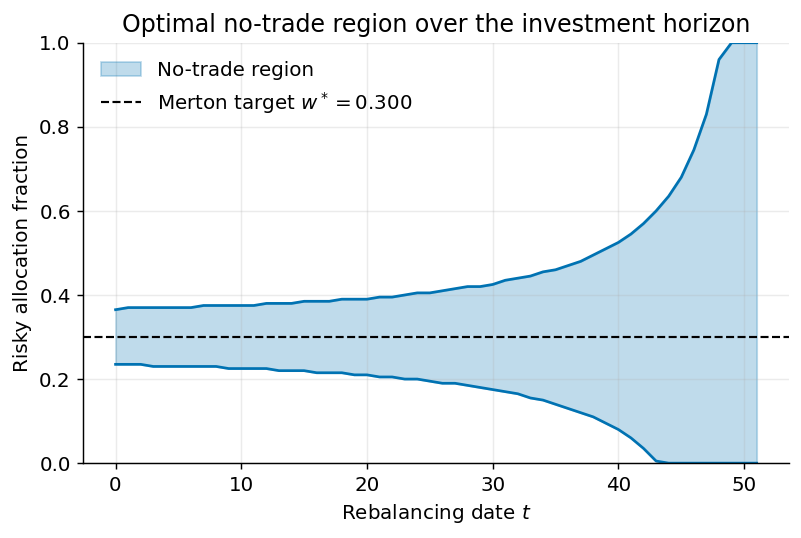

In [3]:
viz.plot_no_trade_region(sol); plt.show()

## The optimal policy $y^\*(x)$
The policy is *bang-bang to the boundary*: flat at the lower edge for under-allocated states, the identity $y=x$ inside the band, and flat at the upper edge for over-allocated states.

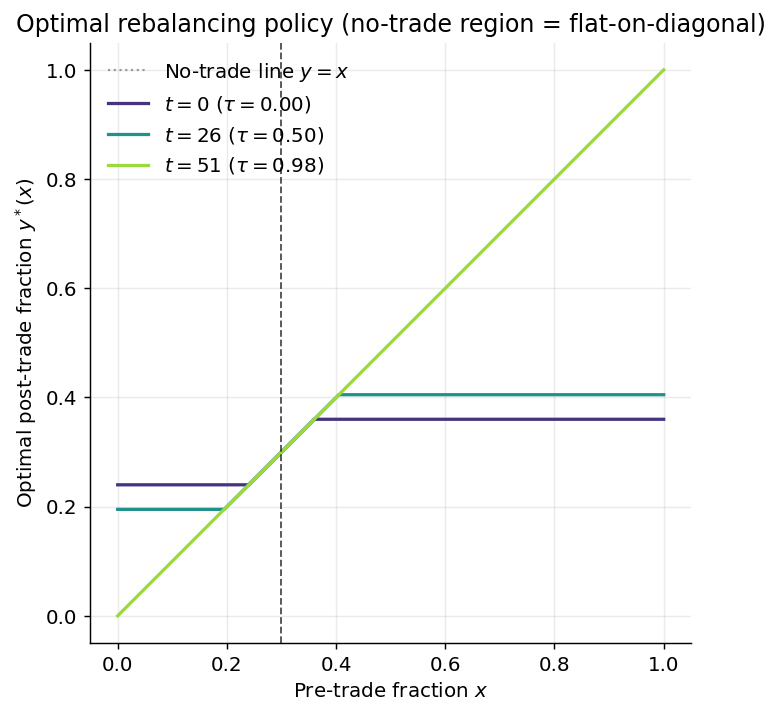

In [4]:
viz.plot_policy_slices(sol); plt.show()

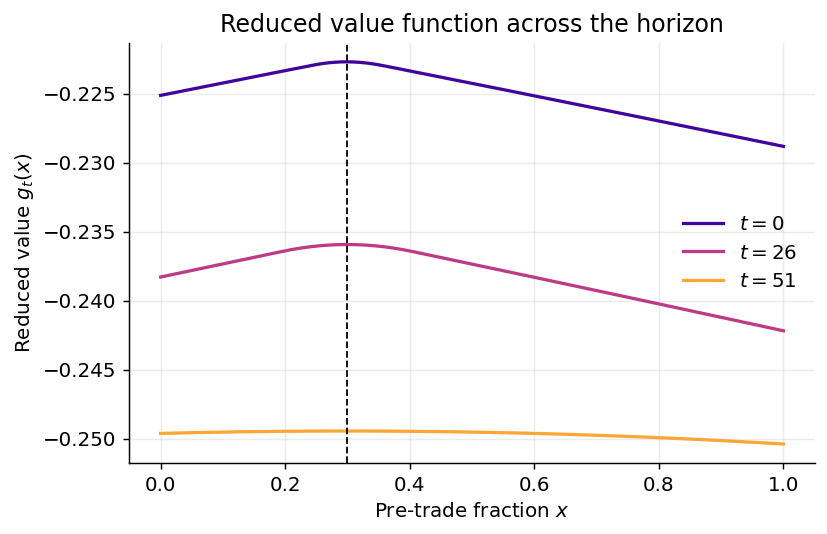

In [5]:
viz.plot_value_function(sol); plt.show()

## Comparative statics
**Band vs cost.** The no-trade region widens with the transaction-cost rate (the classical $\propto tc^{1/3}$ small-cost behaviour).

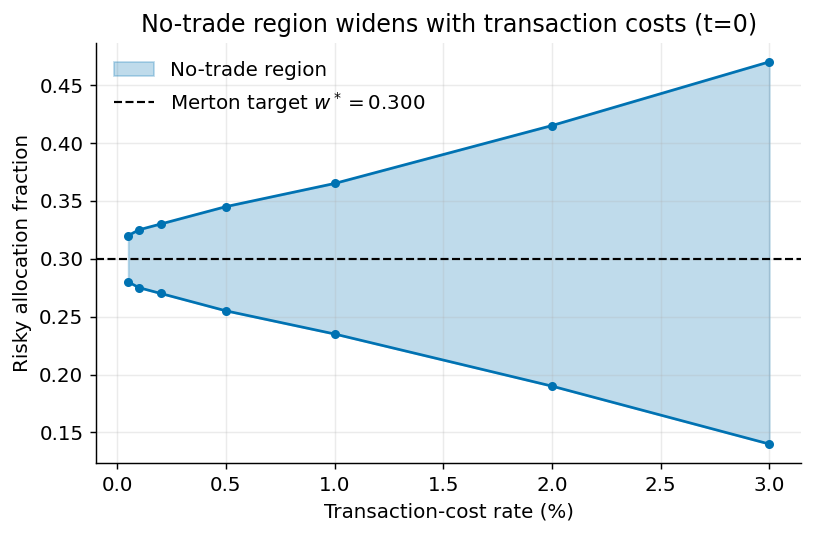

,tc,lower,upper,width
0,0.0005,0.280,0.320,0.040
1,0.0010,0.275,0.325,0.050
2,0.0020,0.270,0.330,0.060
3,0.0050,0.255,0.345,0.090
4,0.0100,0.235,0.365,0.130
5,0.0200,0.190,0.415,0.225
6,0.0300,0.140,0.470,0.330


In [6]:
_, (tc_levels, lo, hi) = viz.plot_band_vs_cost(cfg); plt.show()
pd.DataFrame({'tc':tc_levels,'lower':lo,'upper':hi,'width':hi-lo})

**Band vs risk aversion.** Higher $\gamma$ lowers the target weight and tightens the band.

In [7]:
from dataclasses import replace
rows=[]
for g in [2,3,5,8,12]:
    s = solve(replace(cfg, gamma=float(g)))
    l,h = s.no_trade_band(0)
    rows.append({'gamma':g,'w*':replace(cfg,gamma=float(g)).merton_fraction,
                 'lower':l,'upper':h,'width':h-l})
pd.DataFrame(rows)

,gamma,w*,lower,upper,width
0,2,0.7500,0.615,0.885,0.270
1,3,0.5000,0.400,0.600,0.200
2,5,0.3000,0.235,0.365,0.130
3,8,0.1875,0.140,0.235,0.095
4,12,0.1250,0.090,0.160,0.070


**Takeaway.** Proportional costs convert the single Merton point into a band of inaction whose width scales with cost and shrinks with risk aversion — reproducing the classical Davis–Norman / Constantinides picture. Next we ask whether a neural network can imitate this policy (**03_ml_imitation**).